# 4. Median of Two Sorted Arrays
**Difficulty:** 🔴 Hard · **Topic:** Binary Search · **Pattern:** [Partition Search](README.md) · **LeetCode:** https://leetcode.com/problems/median-of-two-sorted-arrays/

## 💡 Concepts

**Core concept(s):** **Partition search** — binary search for a *cut* through both arrays, not for a value.

**Why it applies here:**
- The median splits the merged array into a left half and a right half of equal size (the left half gets one extra element when the total is odd).
- You never need the merged array itself. You only need to know **how many elements of each array sit in the left half**.
- If the left half takes `i` elements from the smaller array `A`, it must take `j = half - i` from `B`. So there is only **one unknown, `i`**, and it can be binary searched.

**Key intuition:**
- A cut `(i, j)` is correct when every value on the left is `<=` every value on the right.
- Both arrays are sorted, so that check needs only the four values next to the cuts: `A[i-1] <= B[j]` and `B[j-1] <= A[i]`.
- If `A[i-1] > B[j]`, the cut took too much of `A`: move `i` left. If `B[j-1] > A[i]`, it took too little: move `i` right. That one-directional answer is what makes binary search possible.

---

### 📚 What is a Median?
- The **median** is the middle value of a sorted list.
- Odd length: the single middle element, e.g. `[1, 2, 3]` → `2`.
- Even length: the average of the two middle elements, e.g. `[1, 2, 3, 4]` → `(2 + 3) / 2 = 2.5`.
- Half the values are `<=` the median and half are `>=` it. This "equal halves" view is what the partition approach uses.
- **In Python:** `statistics.median(values)` computes it after sorting (used only as a reference in the tests).

### 📚 What is Merging Two Sorted Arrays (Two Pointers)?
- Keep one pointer per array, both starting at index 0.
- Compare the two pointed-at values, take the smaller one, and advance that pointer.
- This produces the merged sorted order without ever re-sorting.
- **Complexity:** each element is taken once → **O(m + n)** time; storing the merged list costs **O(m + n)** space.
- **In Python:** two integer indices and a `list` (or just two variables if you only need the last values taken).

### 📚 What is Binary Search?
- Binary search finds a target in a **sorted** search space by halving it every step.
- Look at the middle; a comparison tells you which half can still contain the answer; drop the other half.
- **Complexity:** a space of size `k` shrinks to nothing after about `log2(k)` steps → **O(log k)** time, **O(1)** space.
- Here the search space is not a list of values but the **cut positions** `i = 0 .. m` in the smaller array.
- **In Python:** a `while lo <= hi` loop with `mid = (lo + hi) // 2`. (`bisect` searches for a value, not a cut, so it does not fit directly.)

### 📚 What is a Partition (Cut)?
- A **cut** at position `i` splits an array into `A[:i]` (left) and `A[i:]` (right). `i` can be `0` (nothing on the left) up to `len(A)` (everything on the left).
- Two cuts, one per array, split the combined values into a left group and a right group.
- The cut is **valid** when `max(left group) <= min(right group)`. Then the left group is exactly the smallest `half` values, and the median sits on the boundary.

### 📚 What is a Sentinel (±infinity)?
- A **sentinel** is a fake value placed past the end of an array so edge cuts need no special case.
- If the cut is at `i = 0`, there is no `A[i-1]`; treat it as `-inf` so it never loses a "left <= right" check.
- If the cut is at `i = m`, there is no `A[i]`; treat it as `+inf`.
- **In Python:** `float("-inf")` and `float("inf")` compare correctly against any int.

---

**Prerequisite knowledge:**
- Classic binary search on a sorted array.
- The two-pointer merge step from merge sort.

## 📝 Problem

Given two sorted arrays `nums1` (length `m`) and `nums2` (length `n`), return the **median** of all `m + n` values together. The required run time is `O(log (m + n))`.

**Example 1**
```
nums1 = [1, 3], nums2 = [2]  ->  2.0
merged = [1, 2, 3]; the middle value is 2
```

**Example 2**
```
nums1 = [1, 2], nums2 = [3, 4]  ->  2.5
merged = [1, 2, 3, 4]; (2 + 3) / 2 = 2.5
```

**Worked example used throughout this notebook's walkthrough** (invented to show every move of the search)
```
nums1 = [2, 4, 7, 10, 14, 17], nums2 = [8, 11, 16, 19]  ->  10.5
merged = [2, 4, 7, 8, 10 | 11, 14, 16, 17, 19]; (10 + 11) / 2 = 10.5
```

**Constraints:** `0 <= m, n <= 1000`, `1 <= m + n <= 2000`, `-10^6 <= nums1[i], nums2[i] <= 10^6`. Either array may be empty, but not both.

> Three approaches: merge everything (`O(m + n)` time and space), walk two pointers only to the middle (`O(m + n)` time, `O(1)` space), then binary search the cut in the smaller array (`O(log min(m, n))`).

In [1]:
from typing import List

### Approach 1 — Brute Force: merge, then pick the middle

**Idea:**
1. Merge the two sorted arrays with two pointers into one sorted list (the merge step of merge sort).
2. If the total length `t` is odd, return `merged[t // 2]`.
3. If it is even, return the average of `merged[t // 2 - 1]` and `merged[t // 2]`.

**Time complexity:** `O(m + n)` — every element is copied into `merged` once.

**Space complexity:** `O(m + n)` — the merged list holds every element.

In [2]:
def find_median_merge(nums1: List[int], nums2: List[int]) -> float:
    merged = []
    i = j = 0
    while i < len(nums1) and j < len(nums2):   # take the smaller front value each time
        if nums1[i] <= nums2[j]:
            merged.append(nums1[i]); i += 1
        else:
            merged.append(nums2[j]); j += 1
    merged.extend(nums1[i:])                   # one array ran out: the rest of the other is already sorted
    merged.extend(nums2[j:])
    t = len(merged)
    mid = t // 2
    if t % 2:                                  # odd: one middle element
        return float(merged[mid])
    return (merged[mid - 1] + merged[mid]) / 2 # even: average the two middle elements

### Approach 2 — Better: walk two pointers only to the middle

**Idea:**
- The median only needs the values at merged positions `t // 2 - 1` and `t // 2`. Everything after them is wasted work, and so is storing everything before them.
- Run the same two-pointer merge, but keep only the last two values taken (`prev`, `cur`) and stop after `t // 2 + 1` steps.
- Odd `t`: the answer is `cur`. Even `t`: the answer is `(prev + cur) / 2`.

**Time complexity:** `O(m + n)` — exactly `t // 2 + 1` steps, about half of Approach 1's, but still linear.

**Space complexity:** `O(1)` — two indices and two values, no merged list.

In [3]:
def find_median_two_pointer(nums1: List[int], nums2: List[int]) -> float:
    m, n = len(nums1), len(nums2)
    t = m + n
    i = j = 0
    prev = cur = 0
    for _ in range(t // 2 + 1):                # walk to merged index t // 2, no further
        prev = cur                             # remember the value one position back
        if i < m and (j >= n or nums1[i] <= nums2[j]):
            cur = nums1[i]; i += 1             # nums1 has the smaller front value (or nums2 is used up)
        else:
            cur = nums2[j]; j += 1
    if t % 2:
        return float(cur)                      # odd: merged[t // 2]
    return (prev + cur) / 2                    # even: average of merged[t // 2 - 1] and merged[t // 2]

### Approach 3 — Partition Search on the smaller array (optimal · pattern template)

**Idea:** the [Partition Search](README.md) template.
1. Let `A` be the **smaller** array (swap if needed), `m = len(A) <= n = len(B)`.
2. The left half must hold `half = (m + n + 1) // 2` values (the `+ 1` gives the left half the extra value when the total is odd).
3. Binary search `i`, the number of values the left half takes from `A`, over `0 .. m`. Then `j = half - i` values come from `B`.
4. Read the four boundary values, with sentinels at the edges: `a_left = A[i-1]` (or `-inf`), `a_right = A[i]` (or `+inf`), and the same for `B` at `j`.
5. If `a_left <= b_right` and `b_left <= a_right`, the cut is valid:
   - odd total → `max(a_left, b_left)`;
   - even total → `(max(a_left, b_left) + min(a_right, b_right)) / 2`.
6. If `a_left > b_right`, too many values came from `A`: `hi = i - 1`. Otherwise (`b_left > a_right`) too few: `lo = i + 1`.

**Why the smaller array?** With `m <= n`, every `i` in `0 .. m` gives `j = half - i` inside `0 .. n`, so `B[j-1]` and `B[j]` never go out of range. It also makes the search `O(log min(m, n))`.

**Time complexity:** `O(log min(m, n))` — each step halves the range of possible cuts in the smaller array.

**Space complexity:** `O(1)` — a handful of indices and four boundary values.

In [4]:
def find_median_partition(nums1: List[int], nums2: List[int]) -> float:
    A, B = nums1, nums2
    if len(A) > len(B):
        A, B = B, A                            # search the smaller array: keeps j in range, O(log min(m, n))
    m, n = len(A), len(B)
    half = (m + n + 1) // 2                    # size of the left half (gets the extra value when the total is odd)
    lo, hi = 0, m                              # i = how many values the left half takes from A: 0..m
    while lo <= hi:
        i = (lo + hi) // 2                     # cut in A
        j = half - i                           # cut in B: the left half must hold exactly `half` values
        a_left = A[i - 1] if i > 0 else float("-inf")   # sentinels: an empty side never blocks the check
        a_right = A[i] if i < m else float("inf")
        b_left = B[j - 1] if j > 0 else float("-inf")
        b_right = B[j] if j < n else float("inf")
        if a_left <= b_right and b_left <= a_right:     # every left value <= every right value: valid cut
            if (m + n) % 2:
                return float(max(a_left, b_left))       # odd: the largest left value is the median
            return (max(a_left, b_left) + min(a_right, b_right)) / 2
        elif a_left > b_right:
            hi = i - 1                         # took too many from A: move the cut left
        else:
            lo = i + 1                         # b_left > a_right: took too few from A: move the cut right
    raise ValueError("inputs must be sorted")  # unreachable for sorted input

In [5]:
# Correctness check
import random
from statistics import median

tests = [
    ([1, 3], [2],                          2.0),    # LeetCode example 1: odd total
    ([1, 2], [3, 4],                       2.5),    # LeetCode example 2: even total
    ([2, 4, 7, 10, 14, 17], [8, 11, 16, 19], 10.5), # worked example: nums1 is longer, so it gets swapped
    ([], [1],                              1.0),    # one array empty, single value
    ([], [2, 3],                           2.5),    # one array empty, even total
    ([5], [],                              5.0),    # the other array empty
    ([1, 2, 3], [4, 5, 6, 7],              4.0),    # all of A before all of B: cut at the end of A
    ([10, 11], [1, 2, 3],                  3.0),    # all of A after all of B: cut at the start of A
    ([1, 1, 1], [1, 1],                    1.0),    # duplicates across both arrays
    ([-5, -3, -1], [-2, 0],                -2.0),   # negatives
    ([1000000], [-1000000],                0.0),    # constraint extremes
]
for a, b, exp in tests:
    r1, r2, r3 = find_median_merge(a, b), find_median_two_pointer(a, b), find_median_partition(a, b)
    print(f"{str(a):22} {str(b):16} -> {r3}")
    assert r1 == r2 == r3 == exp, f"mismatch on {a}, {b}: merge={r1} two_ptr={r2} partition={r3}"

# Randomised cross-check against statistics.median on many shapes, including empty arrays and duplicates
rng = random.Random(4)
for _ in range(2000):
    a = sorted(rng.randint(-50, 50) for _ in range(rng.randint(0, 12)))
    b = sorted(rng.randint(-50, 50) for _ in range(rng.randint(0 if a else 1, 12)))
    ref = median(a + b)
    assert find_median_merge(a, b) == find_median_two_pointer(a, b) == find_median_partition(a, b) == ref, (a, b)
print("2000 random pairs: all three approaches match statistics.median")

print("\nAll tests passed")

[1, 3]                 [2]              -> 2.0
[1, 2]                 [3, 4]           -> 2.5
[2, 4, 7, 10, 14, 17]  [8, 11, 16, 19]  -> 10.5
[]                     [1]              -> 1.0
[]                     [2, 3]           -> 2.5
[5]                    []               -> 5.0
[1, 2, 3]              [4, 5, 6, 7]     -> 4.0
[10, 11]               [1, 2, 3]        -> 3.0
[1, 1, 1]              [1, 1]           -> 1.0
[-5, -3, -1]           [-2, 0]          -> -2.0
[1000000]              [-1000000]       -> 0.0
2000 random pairs: all three approaches match statistics.median

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size and read the **doubling ratio** — how much runtime grows when the size doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(log n)`    | ≈ **1×** |
| `O(n)`        | ≈ **2×** |
| `O(n²)`       | ≈ **4×** |

**Input:** two arrays of `n` values each, where **every value of `nums1` is smaller than every value of `nums2`** (`nums1 = 0 .. n-1`, `nums2 = n .. 2n-1`).
- Both arrays grow, so the smaller one grows too — otherwise the partition search would not grow at all.
- The valid cut is at the very **end** of the smaller array, so the binary search must move right on every step: about `log2(n) + 1` iterations, no lucky early hit. (Interleaved evens/odds would be a bad choice: there the very first guess, the middle, is already the valid cut, so the search stops after one step at every size.)
- The two linear approaches have no early exit on any input: the merge copies all `2n` values, and the two-pointer walk always takes `n + 1` steps.

**Reading the partition row honestly:** one call takes only a few microseconds, too short to time reliably on its own. So that row times **1000 calls** per size. Going from `n = 125,000` to `1,000,000` only adds 3 binary-search steps (about 17 → 20), so its ratio should sit near **1×** (flat), while the two linear approaches roughly double.


merge O(m+n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
   125000 |       5.79 |           n/a
   250000 |      11.90 |         2.05x
   500000 |      26.95 |         2.26x


  1000000 |      55.55 |         2.06x

two-pointer O(m+n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
   125000 |       3.97 |           n/a
   250000 |       7.73 |         1.95x
   500000 |      16.59 |         2.14x


  1000000 |      33.11 |         2.00x

partition O(log min) x1000 calls
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
   125000 |       1.53 |           n/a
   250000 |       1.60 |         1.04x
   500000 |       1.65 |         1.04x
  1000000 |       1.77 |         1.07x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


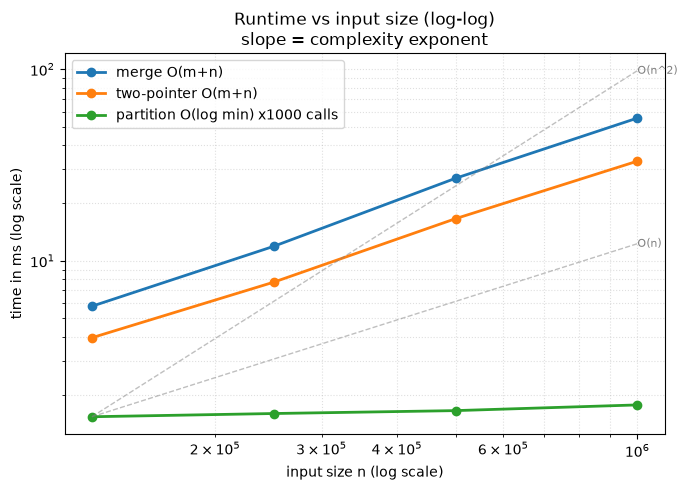

{'merge O(m+n)': [5.790333030745387,
  11.89783401787281,
  26.946500060148537,
  55.55470800027251],
 'two-pointer O(m+n)': [3.9661669870838523,
  7.733750040642917,
  16.58658403903246,
  33.10733404941857],
 'partition O(log min) x1000 calls': [1.534749986603856,
  1.595374895259738,
  1.6520830104127526,
  1.7691249959170818]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (list(range(n)), list(range(n, 2 * n)))   # all of nums1 < all of nums2: the valid cut is at the end of A

def partition_x1000(nums1, nums2):
    for _ in range(1000):                       # one call is microseconds: time 1000 to get above timer noise
        find_median_partition(nums1, nums2)

solutions = {
    "merge O(m+n)": find_median_merge,
    "two-pointer O(m+n)": find_median_two_pointer,
    "partition O(log min) x1000 calls": partition_x1000,
}
sizes = [125_000, 250_000, 500_000, 1_000_000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Partition Search](README.md) — binary search the cut `i` in the smaller array; `j = half - i` is forced, and the four boundary values say whether to move the cut left or right.
- **Search the answer's *position*, not a value:** when the answer is "the boundary between two groups", binary search the boundary. The check `A[i-1] <= B[j]` and `B[j-1] <= A[i]` gives a clear "go left / go right / done".
- **Sentinels remove edge cases:** `-inf` / `+inf` for missing neighbours mean cuts at `0` or at the end need no special branch.
- **Search the smaller array:** keeps `j` inside `B` and makes it `O(log min(m, n))`.
- **Signal:** two sorted arrays plus "median", "k-th smallest", or a required `O(log (m + n))` time.
- **Related problems (variants):** K-th smallest element of two sorted arrays (same cut with `half = k`), Find Median from Data Stream (two heaps, the streaming version of "left half / right half"), Median of a row-wise sorted matrix.
- **Common pitfalls:**
  1. Searching the larger array — `j` can go negative or past `n` and index out of range.
  2. Using `half = (m + n) // 2` with the odd-case answer `max(a_left, b_left)` — the left half is one value short; either use `(m + n + 1) // 2` or take `min(a_right, b_right)` for odd totals, consistently.
  3. Forgetting sentinels, so `i = 0` or `i = m` crashes or compares against the wrong neighbour.
  4. Returning an `int` for odd totals when a float is expected, or using `//` for the even-case average.